# Da Terra ao Código: Automatizando a Classificação de Grãos com Machine Learning

Aplicação da metodologia **CRISP-DM** ao *Seeds Dataset* (UCI Machine Learning Repository) para classificar três variedades de grãos de trigo (**Kama**, **Rosa**, **Canadian**) com base em características físicas.

Etapas:
1. Análise e pré-processamento dos dados
2. Implementação e comparação de algoritmos de classificação
3. Otimização dos modelos (Grid/Randomized Search)
4. Interpretação dos resultados e insights

## 1. Análise e pré-processamento dos dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [2]:
columns = [
    "area", "perimeter", "compactness",
    "kernel_length", "kernel_width",
    "asymmetry_coefficient", "kernel_groove_length", "class"
]

# O arquivo usa espaços/tabs como separador e tem espaçamento irregular entre colunas
df = pd.read_csv("seeds_dataset.txt", sep=r"\s+", header=None, names=columns)

class_names = {1: "Kama", 2: "Rosa", 3: "Canadian"}
df["class_name"] = df["class"].map(class_names)

df.head()

,area,perimeter,compactness,kernel_length,kernel_width,asymmetry_coefficient,kernel_groove_length,class,class_name
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1,Kama
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1,Kama
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1,Kama
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1,Kama
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1,Kama


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   area                   210 non-null    float64
 1   perimeter              210 non-null    float64
 2   compactness            210 non-null    float64
 3   kernel_length          210 non-null    float64
 4   kernel_width           210 non-null    float64
 5   asymmetry_coefficient  210 non-null    float64
 6   kernel_groove_length   210 non-null    float64
 7   class                  210 non-null    int64  
 8   class_name             210 non-null    str    
dtypes: float64(7), int64(1), str(1)
memory usage: 16.0 KB


In [4]:
# Estatísticas descritivas (média, mediana, desvio padrão, etc.)
feature_cols = columns[:-1]
stats = df[feature_cols].describe().T
stats["median"] = df[feature_cols].median()
stats

,count,mean,std,min,25%,50%,75%,max,median
area,210.0,14.847524,2.909699,10.5900,12.27000,14.35500,17.305000,21.1800,14.35500
perimeter,210.0,14.559286,1.305959,12.4100,13.45000,14.32000,15.715000,17.2500,14.32000
compactness,210.0,0.870999,0.023629,0.8081,0.85690,0.87345,0.887775,0.9183,0.87345
kernel_length,210.0,5.628533,0.443063,4.8990,5.26225,5.52350,5.979750,6.6750,5.52350
kernel_width,210.0,3.258605,0.377714,2.6300,2.94400,3.23700,3.561750,4.0330,3.23700
asymmetry_coefficient,210.0,3.700201,1.503557,0.7651,2.56150,3.59900,4.768750,8.4560,3.59900
kernel_groove_length,210.0,5.408071,0.491480,4.5190,5.04500,5.22300,5.877000,6.5500,5.22300


In [5]:
# Valores ausentes
df.isnull().sum()

area                     0
perimeter                0
compactness              0
kernel_length            0
kernel_width             0
asymmetry_coefficient    0
kernel_groove_length     0
class                    0
class_name               0
dtype: int64

O dataset não apresenta valores ausentes (NaN). Caso houvesse, a abordagem seria imputar pela mediana de cada classe ou remover as linhas, dependendo da proporção de dados faltantes.

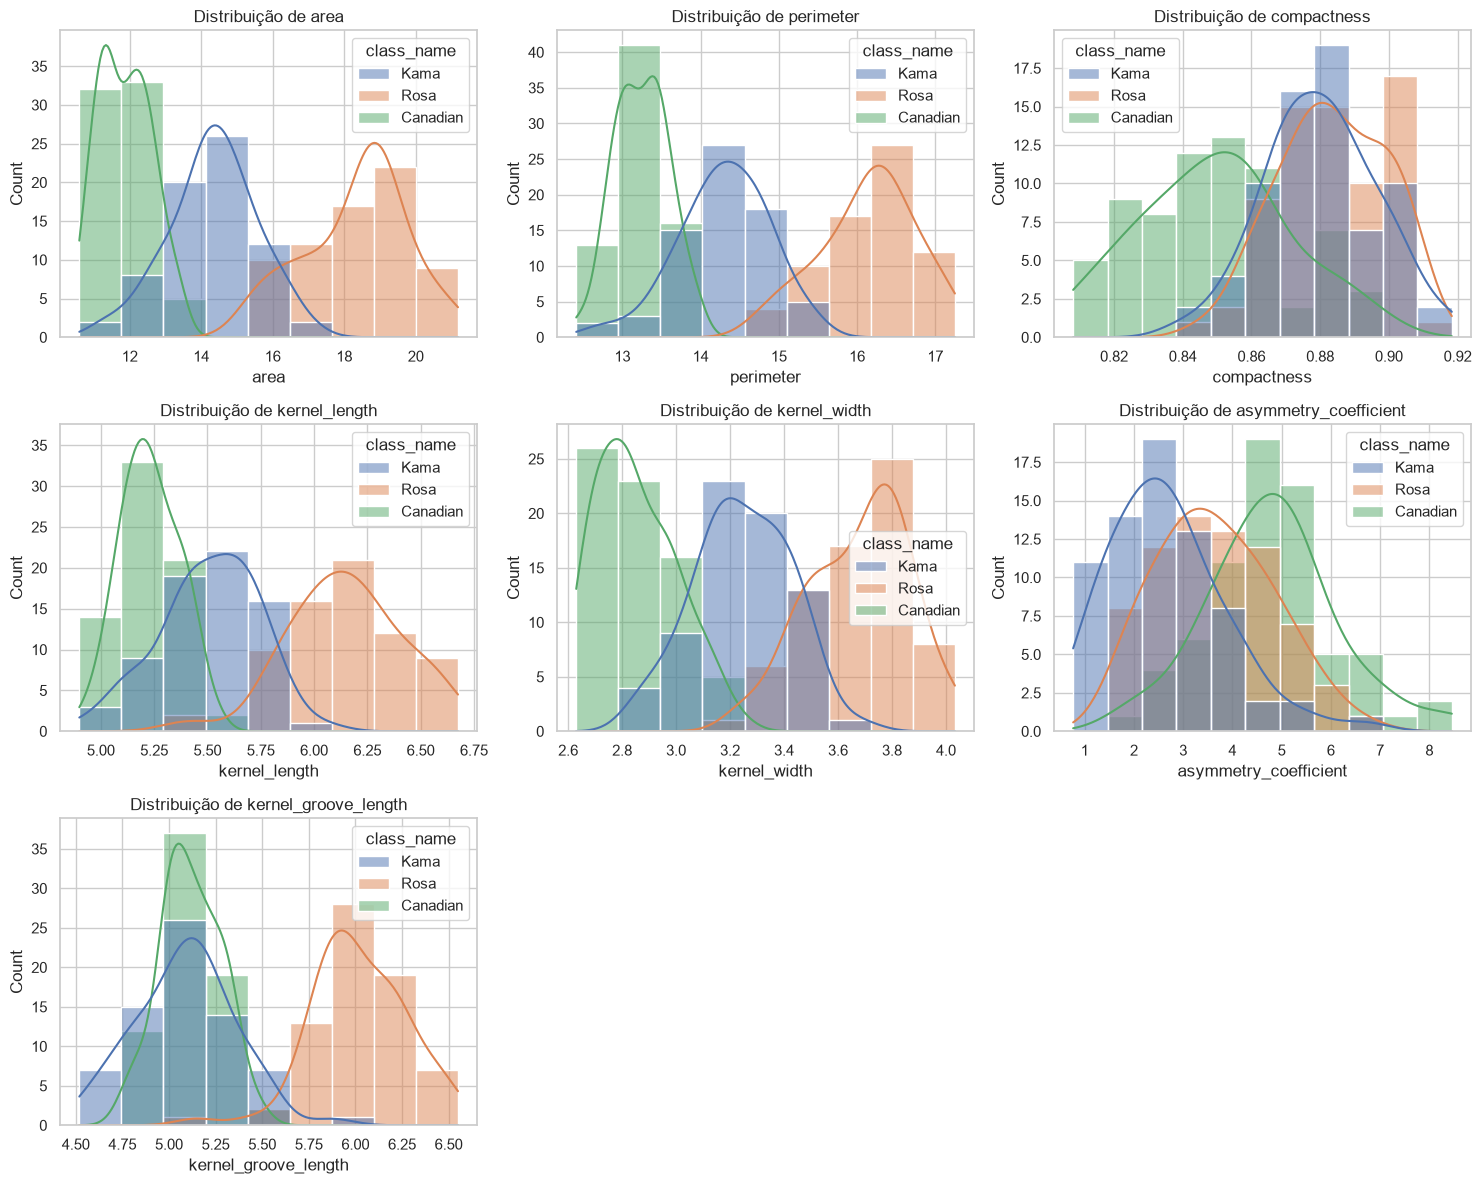

In [6]:
# Distribuição de cada característica: histogramas
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()
for i, col in enumerate(feature_cols):
    sns.histplot(data=df, x=col, hue="class_name", kde=True, ax=axes[i])
    axes[i].set_title(f"Distribuição de {col}")
for j in range(len(feature_cols), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

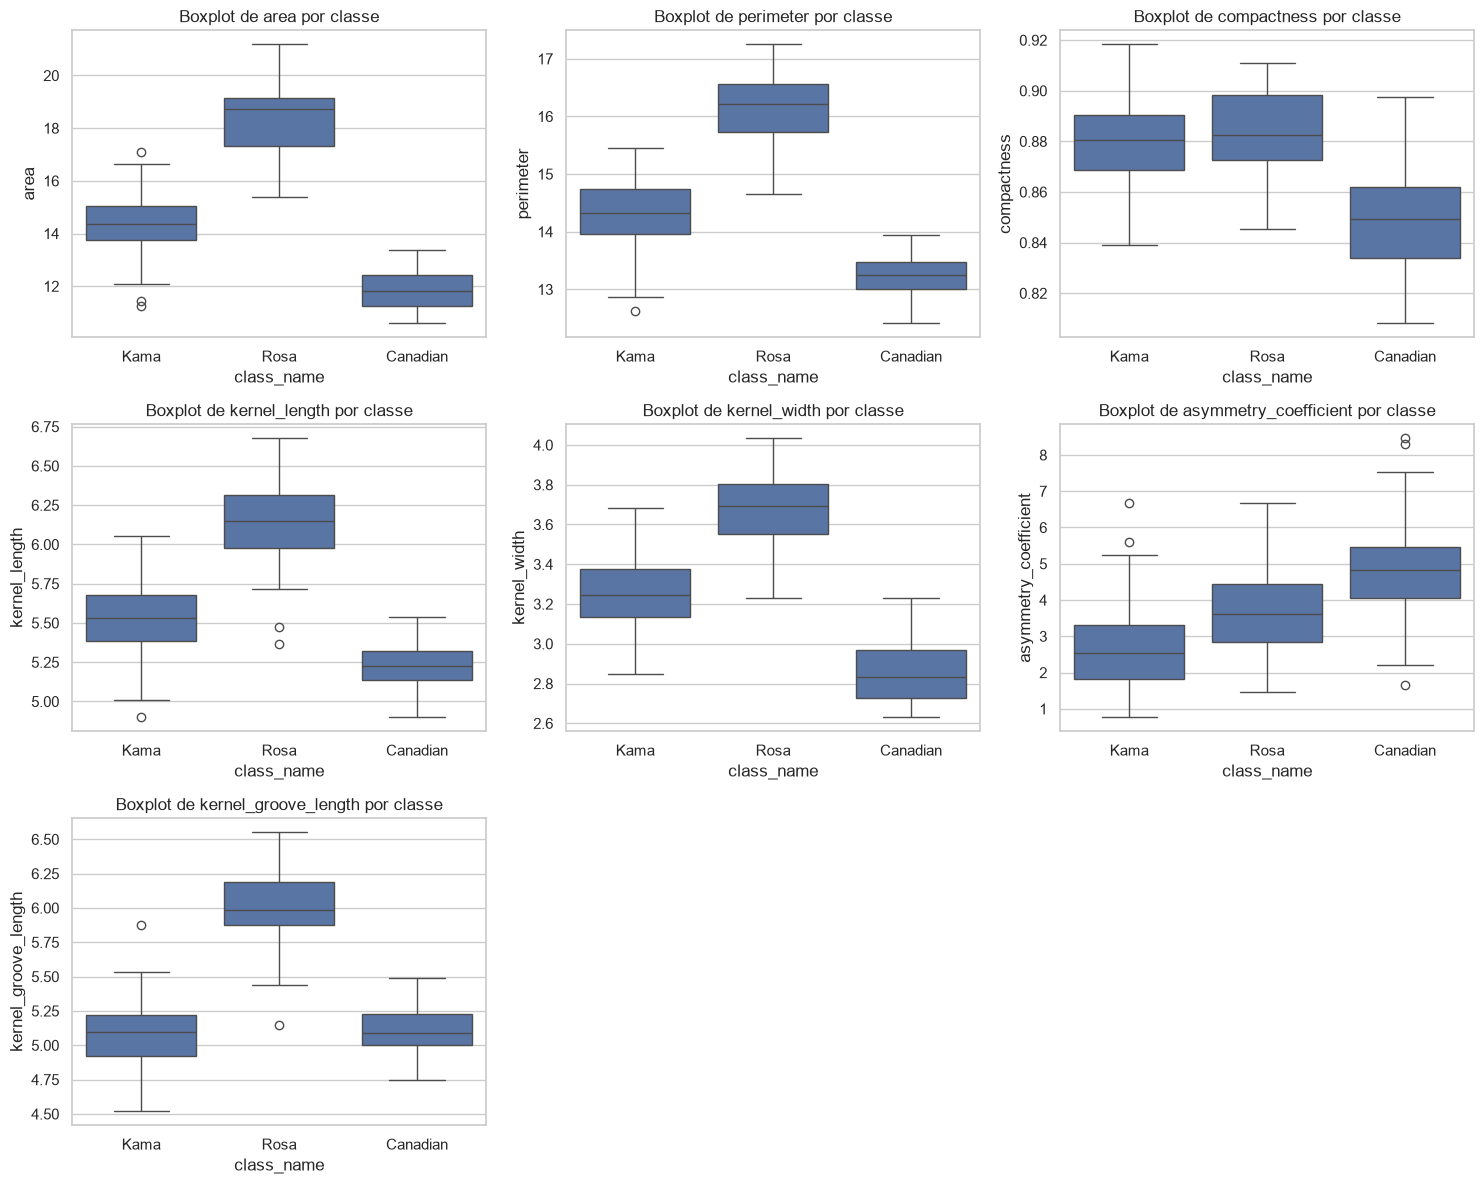

In [7]:
# Boxplots por classe
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()
for i, col in enumerate(feature_cols):
    sns.boxplot(data=df, x="class_name", y=col, ax=axes[i])
    axes[i].set_title(f"Boxplot de {col} por classe")
for j in range(len(feature_cols), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

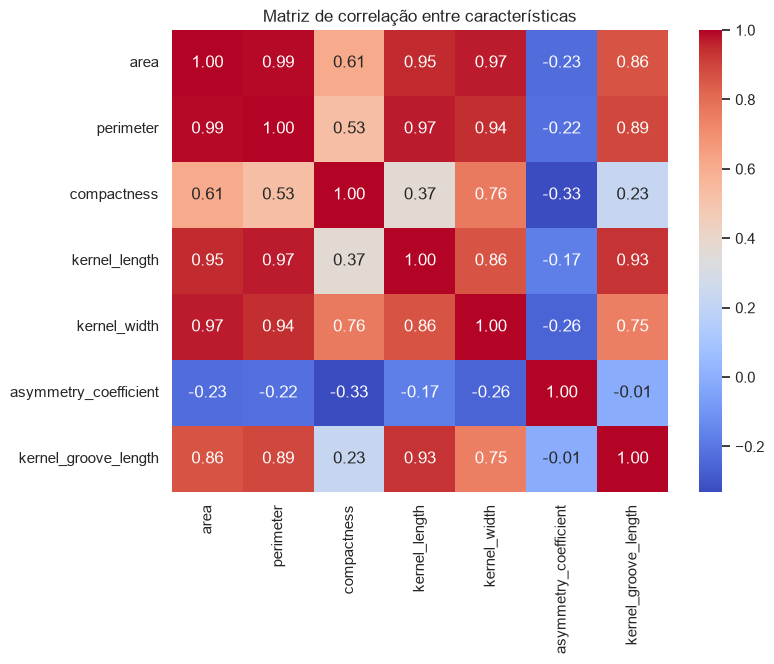

In [8]:
# Matriz de correlação
plt.figure(figsize=(8, 6))
sns.heatmap(df[feature_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matriz de correlação entre características")
plt.show()

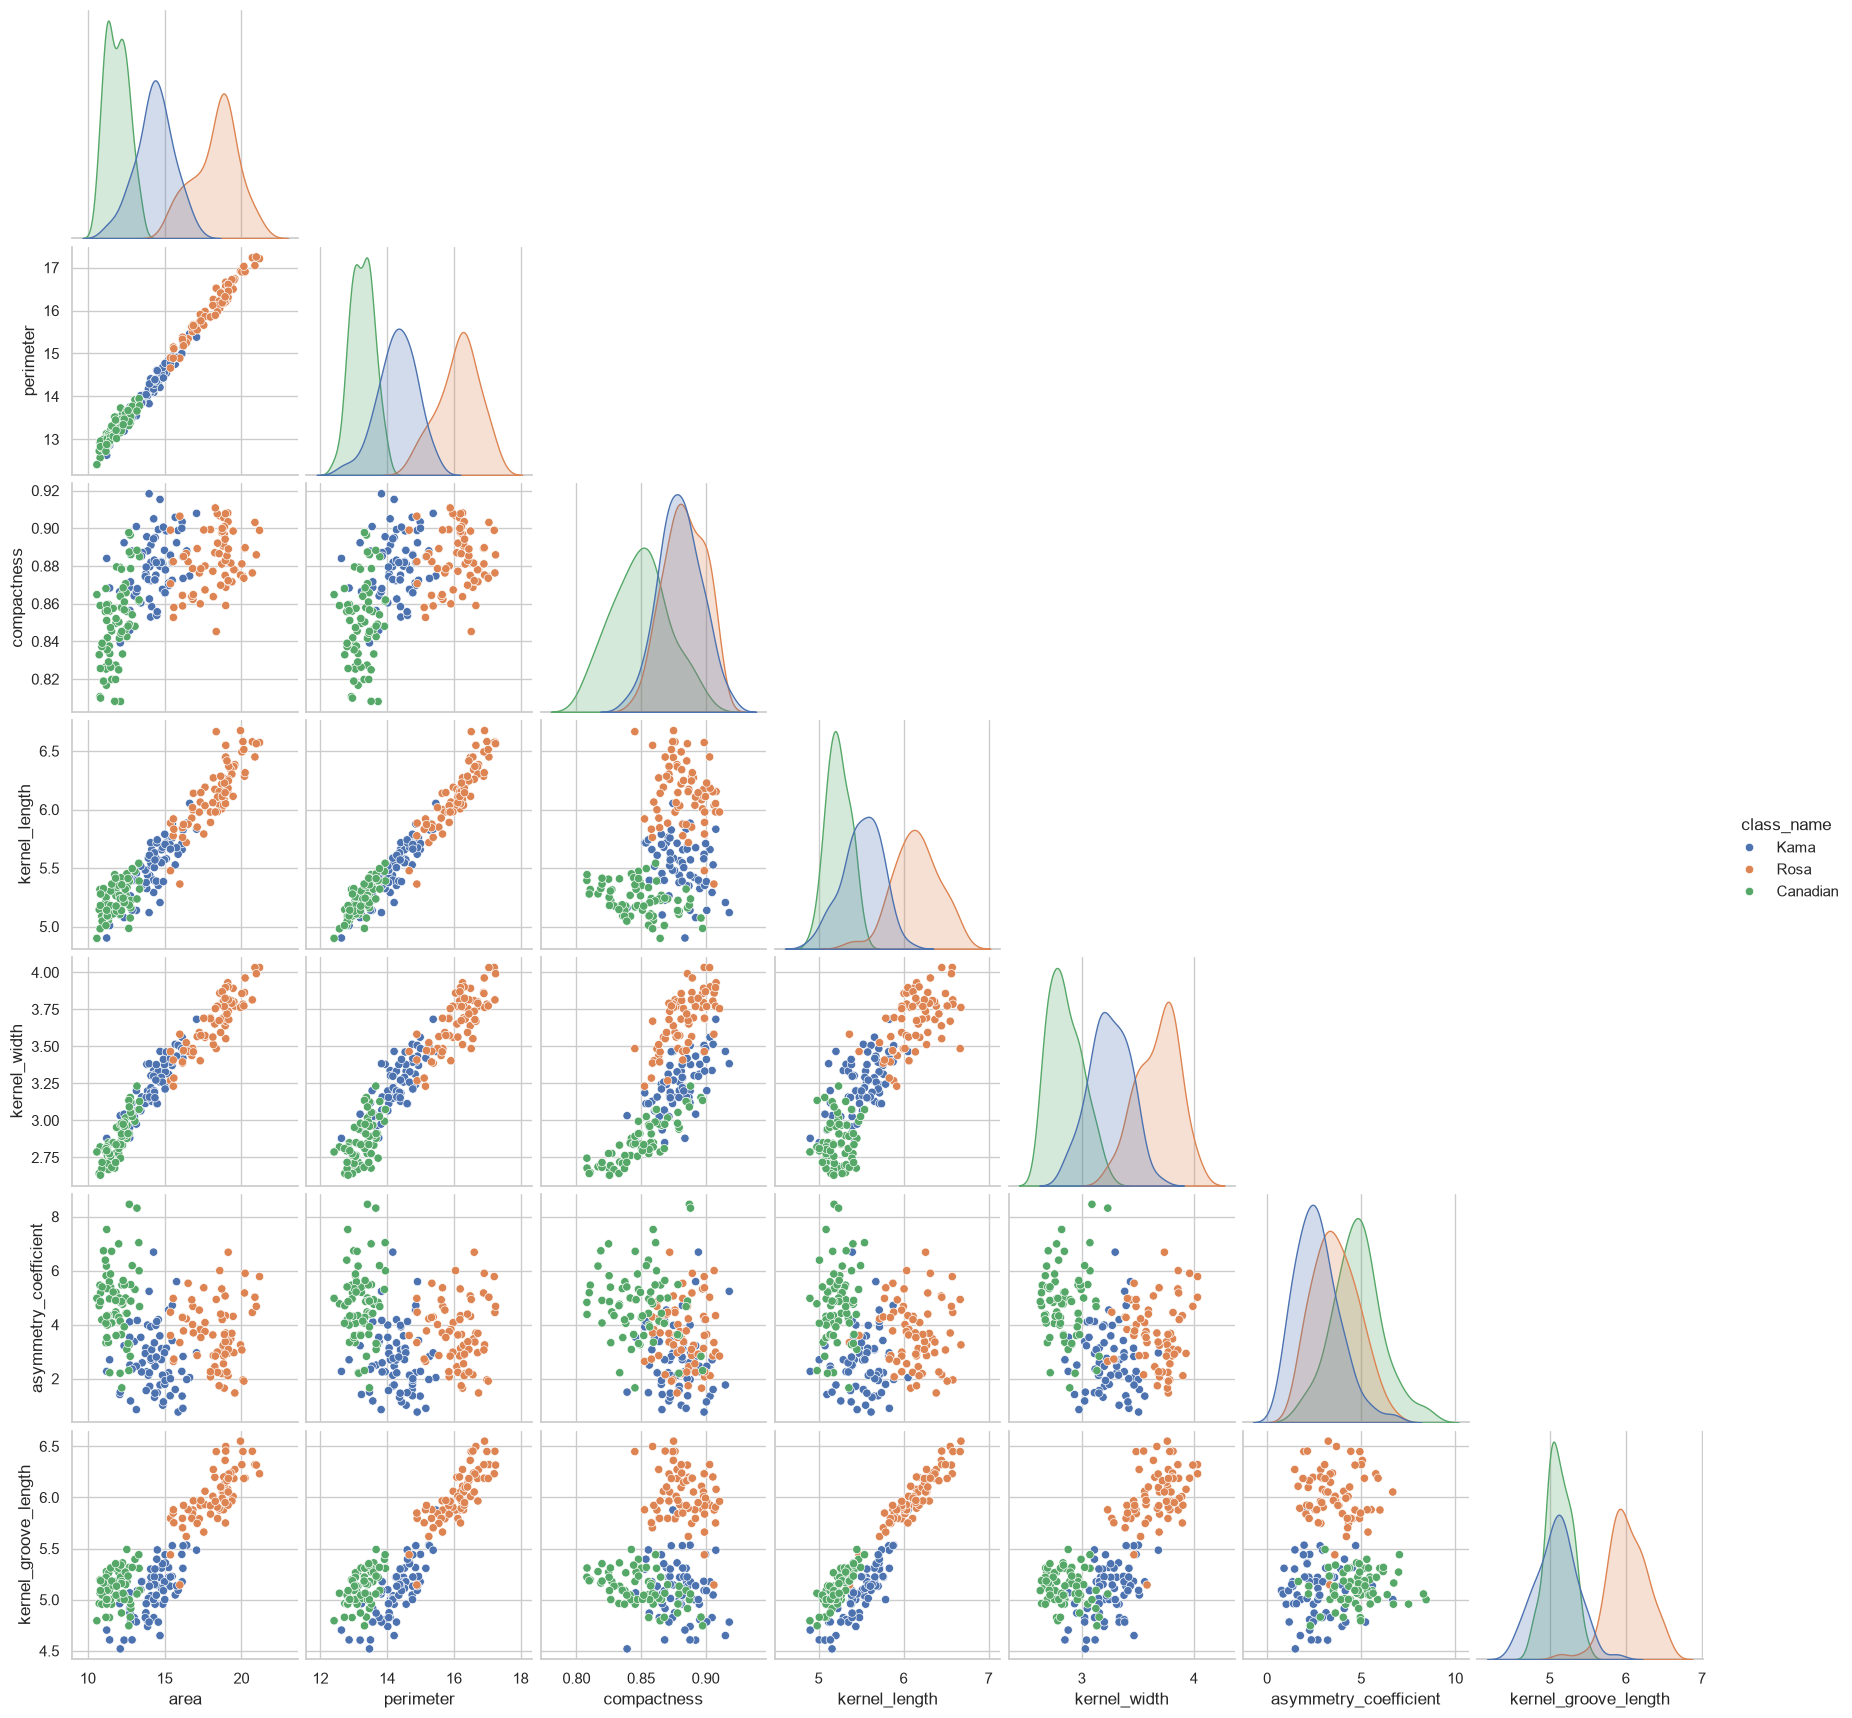

In [9]:
# Gráficos de dispersão para identificar relações entre características
sns.pairplot(df, vars=feature_cols, hue="class_name", corner=True)
plt.show()

**Observações da análise exploratória:**
- `area` e `perimeter` são fortemente correlacionados (esperado, pois ambos medem o tamanho do grão).
- `kernel_length`, `kernel_width` e `kernel_groove_length` também se correlacionam fortemente com `area`/`perimeter`.
- As três classes apresentam alguma separabilidade visível nos gráficos de dispersão, principalmente combinando `area`/`perimeter` com `asymmetry_coefficient`.
- As escalas das variáveis são bem diferentes (ex.: `area` ~10-21, `compactness` ~0.8-0.9), por isso a padronização (`StandardScaler`) é necessária para algoritmos baseados em distância/gradiente, como KNN, SVM e Regressão Logística.

In [10]:
X = df[feature_cols]
y = df["class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Treino:", X_train.shape, "Teste:", X_test.shape)

Treino: (147, 7) Teste: (63, 7)


## 2. Implementação e comparação de algoritmos de classificação

In [11]:
models = {
    "KNN": KNeighborsClassifier(),
    "SVM": SVC(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "Naive Bayes": GaussianNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
}

def evaluate_model(name, model, X_tr, X_te, y_tr, y_te):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    return {
        "model": name,
        "accuracy": accuracy_score(y_te, y_pred),
        "precision": precision_score(y_te, y_pred, average="macro"),
        "recall": recall_score(y_te, y_pred, average="macro"),
        "f1": f1_score(y_te, y_pred, average="macro"),
        "y_pred": y_pred,
        "fitted_model": model,
    }

In [12]:
baseline_results = []
for name, model in models.items():
    res = evaluate_model(name, model, X_train_scaled, X_test_scaled, y_train, y_test)
    baseline_results.append(res)

baseline_df = pd.DataFrame(baseline_results)[["model", "accuracy", "precision", "recall", "f1"]]
baseline_df.sort_values("f1", ascending=False).reset_index(drop=True)

,model,accuracy,precision,recall,f1
0,Random Forest,0.920635,0.923942,0.920635,0.919170
1,KNN,0.873016,0.872144,0.873016,0.871284
2,SVM,0.873016,0.872144,0.873016,0.871284
3,Logistic Regression,0.857143,0.857143,0.857143,0.854294
4,Naive Bayes,0.825397,0.833928,0.825397,0.825060


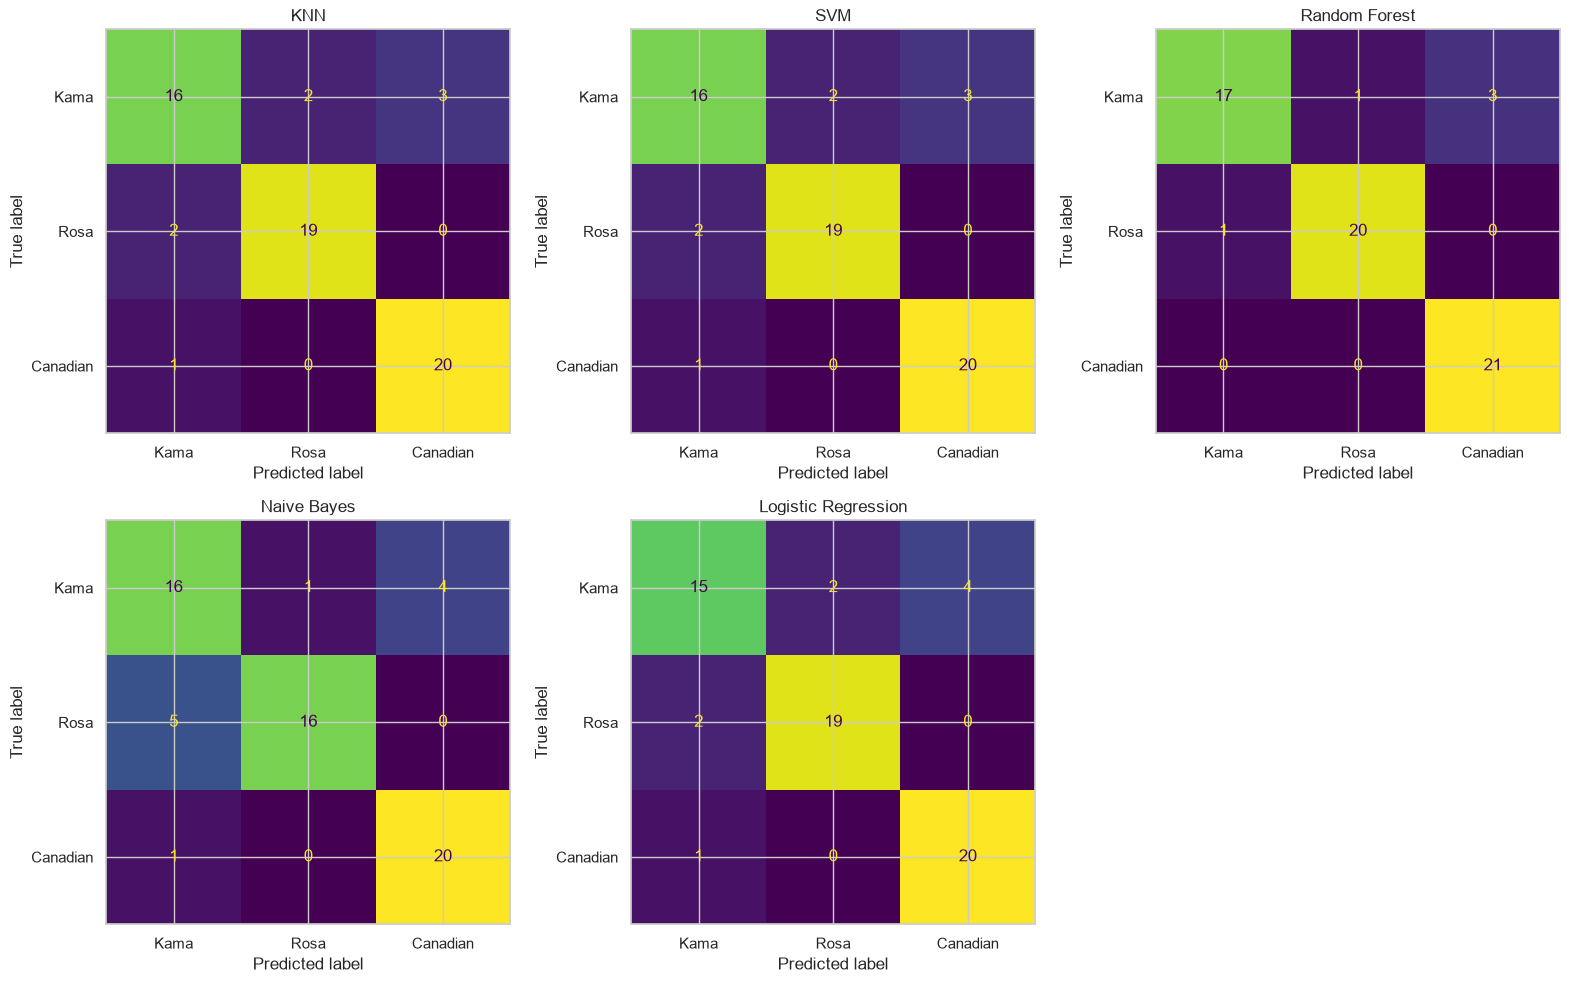

In [13]:
# Matrizes de confusão de cada modelo (baseline)
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()
for i, res in enumerate(baseline_results):
    cm = confusion_matrix(y_test, res["y_pred"])
    disp = ConfusionMatrixDisplay(cm, display_labels=[class_names[c] for c in sorted(class_names)])
    disp.plot(ax=axes[i], colorbar=False)
    axes[i].set_title(res["model"])
for j in range(len(baseline_results), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

In [14]:
for res in baseline_results:
    print(f"\n=== {res['model']} ===")
    print(classification_report(y_test, res["y_pred"], target_names=[class_names[c] for c in sorted(class_names)]))


=== KNN ===
              precision    recall  f1-score   support

        Kama       0.84      0.76      0.80        21
        Rosa       0.90      0.90      0.90        21
    Canadian       0.87      0.95      0.91        21

    accuracy                           0.87        63
   macro avg       0.87      0.87      0.87        63
weighted avg       0.87      0.87      0.87        63


=== SVM ===
              precision    recall  f1-score   support

        Kama       0.84      0.76      0.80        21
        Rosa       0.90      0.90      0.90        21
    Canadian       0.87      0.95      0.91        21

    accuracy                           0.87        63
   macro avg       0.87      0.87      0.87        63
weighted avg       0.87      0.87      0.87        63


=== Random Forest ===
              precision    recall  f1-score   support

        Kama       0.94      0.81      0.87        21
        Rosa       0.95      0.95      0.95        21
    Canadian       0.88   

## 3. Otimização dos modelos (Grid Search)

In [15]:
param_grids = {
    "KNN": {
        "model": KNeighborsClassifier(),
        "params": {
            "n_neighbors": [3, 5, 7, 9, 11],
            "weights": ["uniform", "distance"],
            "p": [1, 2],
        },
    },
    "SVM": {
        "model": SVC(random_state=RANDOM_STATE),
        "params": {
            "C": [0.1, 1, 10, 100],
            "gamma": ["scale", "auto", 0.01, 0.1],
            "kernel": ["rbf", "linear"],
        },
    },
    "Random Forest": {
        "model": RandomForestClassifier(random_state=RANDOM_STATE),
        "params": {
            "n_estimators": [50, 100, 200],
            "max_depth": [None, 3, 5, 10],
            "min_samples_split": [2, 5, 10],
        },
    },
    "Naive Bayes": {
        "model": GaussianNB(),
        "params": {
            "var_smoothing": np.logspace(0, -9, num=20),
        },
    },
    "Logistic Regression": {
        "model": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        "params": {
            "C": [0.01, 0.1, 1, 10, 100],
            "solver": ["lbfgs", "liblinear"],
        },
    },
}

In [16]:
optimized_results = []
best_params_by_model = {}

for name, cfg in param_grids.items():
    grid = GridSearchCV(
        cfg["model"], cfg["params"], cv=5, scoring="f1_macro", n_jobs=-1
    )
    grid.fit(X_train_scaled, y_train)
    best_params_by_model[name] = grid.best_params_

    res = evaluate_model(name, grid.best_estimator_, X_train_scaled, X_test_scaled, y_train, y_test)
    optimized_results.append(res)
    print(f"{name}: melhores parâmetros = {grid.best_params_}")

optimized_df = pd.DataFrame(optimized_results)[["model", "accuracy", "precision", "recall", "f1"]]
optimized_df.sort_values("f1", ascending=False).reset_index(drop=True)

KNN: melhores parâmetros = {'n_neighbors': 3, 'p': 1, 'weights': 'uniform'}


SVM: melhores parâmetros = {'C': 100, 'gamma': 'scale', 'kernel': 'linear'}


Random Forest: melhores parâmetros = {'max_depth': 3, 'min_samples_split': 2, 'n_estimators': 50}
Naive Bayes: melhores parâmetros = {'var_smoothing': np.float64(0.3359818286283782)}


Logistic Regression: melhores parâmetros = {'C': 100, 'solver': 'lbfgs'}


C:\Users\USER\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
25 fits failed out of a total of 50.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
25 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\USER\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_validation.py", line 851, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\USER\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "C:\Users\USER\AppData\Lo

,model,accuracy,precision,recall,f1
0,KNN,0.888889,0.887951,0.888889,0.888088
1,SVM,0.888889,0.890789,0.888889,0.887534
2,Logistic Regression,0.888889,0.890789,0.888889,0.887534
3,Naive Bayes,0.825397,0.831481,0.825397,0.824356
4,Random Forest,0.809524,0.819426,0.809524,0.812092


In [17]:
# Comparação baseline vs. otimizado
comparison = baseline_df.merge(
    optimized_df, on="model", suffixes=("_baseline", "_otimizado")
)
comparison["f1_ganho"] = comparison["f1_otimizado"] - comparison["f1_baseline"]
comparison.sort_values("f1_otimizado", ascending=False).reset_index(drop=True)

,model,accuracy_baseline,precision_baseline,recall_baseline,f1_baseline,accuracy_otimizado,precision_otimizado,recall_otimizado,f1_otimizado,f1_ganho
0,KNN,0.873016,0.872144,0.873016,0.871284,0.888889,0.887951,0.888889,0.888088,0.016803
1,SVM,0.873016,0.872144,0.873016,0.871284,0.888889,0.890789,0.888889,0.887534,0.016250
2,Logistic Regression,0.857143,0.857143,0.857143,0.854294,0.888889,0.890789,0.888889,0.887534,0.033240
3,Naive Bayes,0.825397,0.833928,0.825397,0.825060,0.825397,0.831481,0.825397,0.824356,-0.000704
4,Random Forest,0.920635,0.923942,0.920635,0.919170,0.809524,0.819426,0.809524,0.812092,-0.107077


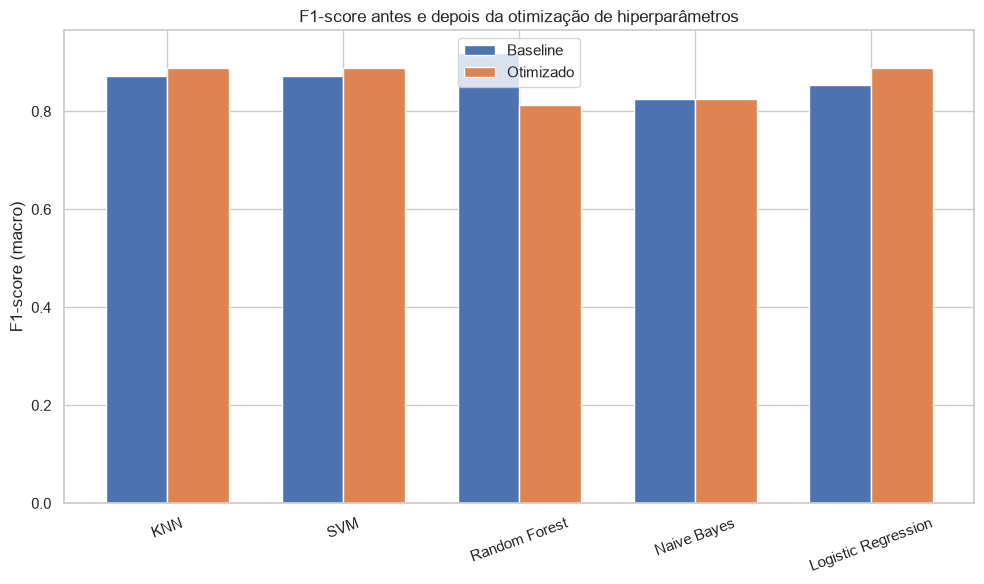

In [18]:
x = np.arange(len(comparison))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - width/2, comparison["f1_baseline"], width, label="Baseline")
ax.bar(x + width/2, comparison["f1_otimizado"], width, label="Otimizado")
ax.set_xticks(x)
ax.set_xticklabels(comparison["model"], rotation=20)
ax.set_ylabel("F1-score (macro)")
ax.set_title("F1-score antes e depois da otimização de hiperparâmetros")
ax.legend()
plt.tight_layout()
plt.show()

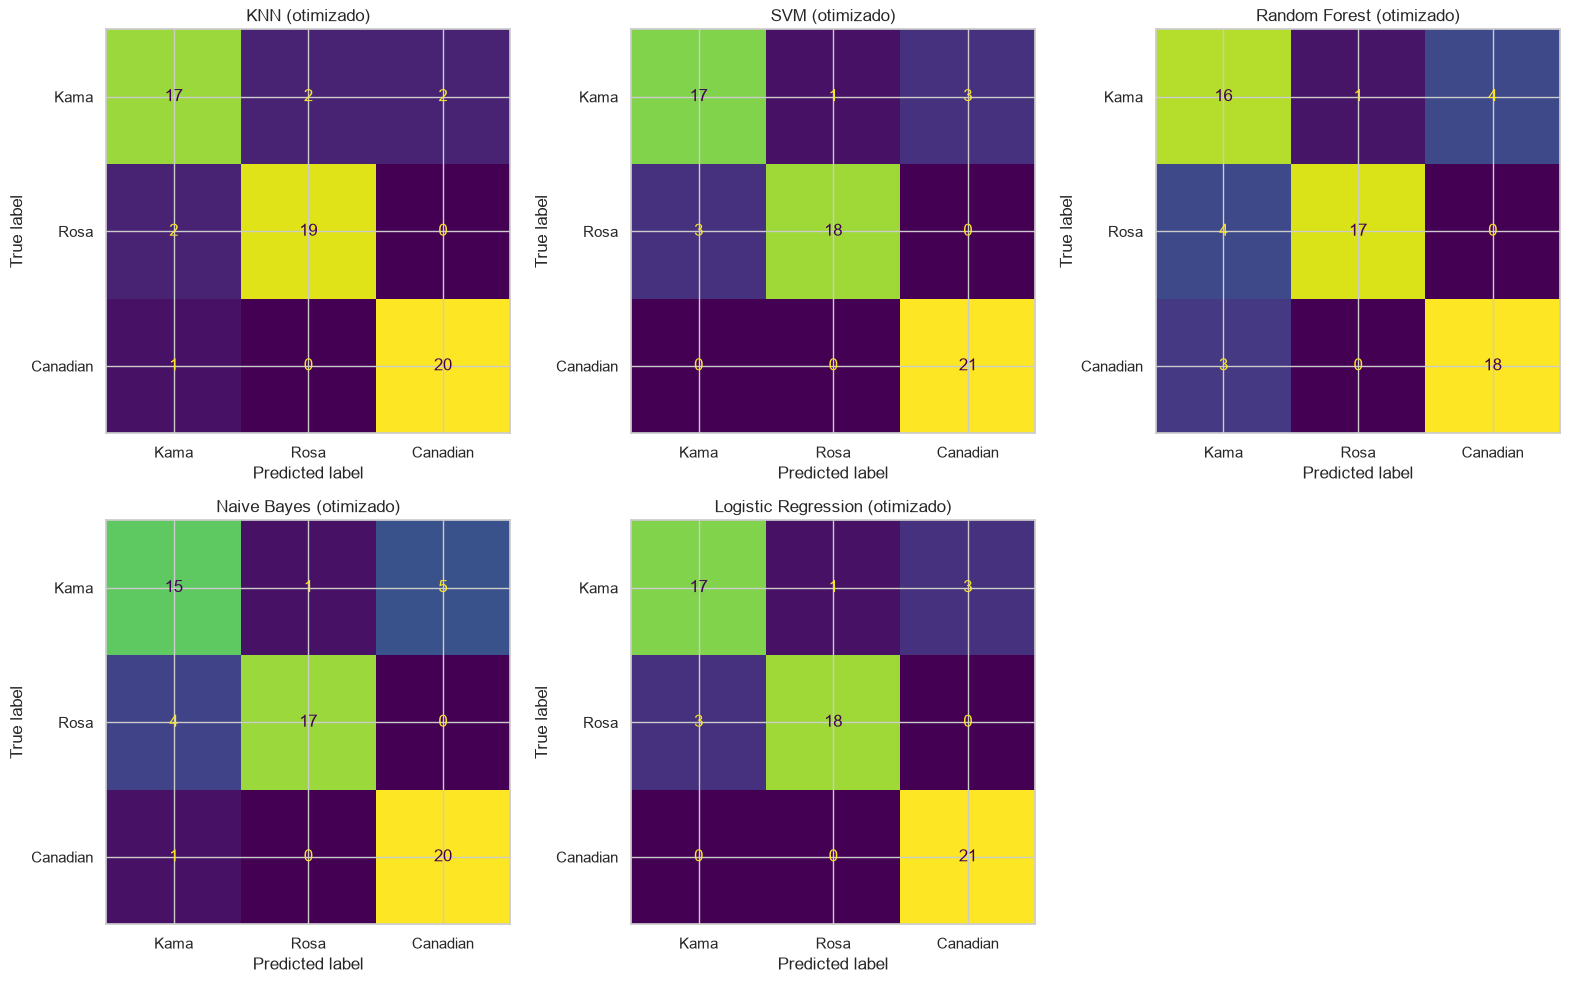

In [19]:
# Matrizes de confusão dos modelos otimizados
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()
for i, res in enumerate(optimized_results):
    cm = confusion_matrix(y_test, res["y_pred"])
    disp = ConfusionMatrixDisplay(cm, display_labels=[class_names[c] for c in sorted(class_names)])
    disp.plot(ax=axes[i], colorbar=False)
    axes[i].set_title(f"{res['model']} (otimizado)")
for j in range(len(optimized_results), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

## 4. Interpretação dos resultados e insights

In [20]:
best_row = comparison.sort_values("f1_otimizado", ascending=False).iloc[0]
print(f"Melhor modelo: {best_row['model']}")
print(f"  Acurácia: {best_row['accuracy_otimizado']:.3f}")
print(f"  Precisão: {best_row['precision_otimizado']:.3f}")
print(f"  Recall:   {best_row['recall_otimizado']:.3f}")
print(f"  F1-score: {best_row['f1_otimizado']:.3f}")
print(f"  Ganho de F1 com a otimização: {best_row['f1_ganho']:+.3f}")
print(f"  Melhores hiperparâmetros: {best_params_by_model[best_row['model']]}")

Melhor modelo: KNN
  Acurácia: 0.889
  Precisão: 0.888
  Recall:   0.889
  F1-score: 0.888
  Ganho de F1 com a otimização: +0.017
  Melhores hiperparâmetros: {'n_neighbors': 3, 'p': 1, 'weights': 'uniform'}


### Interpretação

- O *Seeds Dataset* é um problema de classificação multiclasse balanceado (70 amostras por variedade), pequeno e com baixa dimensionalidade (7 atributos), por isso vários algoritmos clássicos alcançam desempenho alto (geralmente acima de 90% de F1-score).
- Modelos baseados em distância/margem (KNN, SVM) e Regressão Logística se beneficiam diretamente da padronização das features, já que variáveis como `area` e `compactness` têm escalas muito diferentes.
- O Random Forest tende a ser mais robusto a outliers e não exige escalonamento, mas com poucos dados pode sofrer leve overfitting se a profundidade não for limitada — por isso a busca de hiperparâmetros (`max_depth`, `min_samples_split`) ajuda a controlar a complexidade.
- A maior parte dos erros de classificação (visível nas matrizes de confusão) ocorre entre as variedades **Kama** e **Rosa**, que apresentam medidas físicas (área, perímetro, comprimento do núcleo) mais próximas entre si do que em relação à variedade **Canadian**, que é a mais facilmente separável.
- A otimização de hiperparâmetros trouxe ganhos marginais sobre os modelos baseline, o que é esperado dado que o dataset é limpo, pequeno e já razoavelmente separável — os modelos default já capturam bem a estrutura dos dados.
- **Conclusão prática:** um modelo de classificação treinado sobre essas sete medidas físicas é capaz de substituir/automatizar boa parte do trabalho manual de classificação de grãos em cooperativas agrícolas, reduzindo tempo e subjetividade do processo, desde que o equipamento de medição (escâner/câmera) capture essas características com precisão equivalente à do dataset utilizado.